# 11 Disease spreading
## Lockdown strategies

<div style="background-color: #f0f8ff; border: 2px solid #4682b4; padding: 10px;">
<strong>Note:</strong> This notebook contains the code for section 11.4 from the book  

**Simulation of Complex Systems**  
Aykut Argun, Agnese Callegari, and Giovanni Volpe<br>
IOP Publishing, Bristol, UK, 2021<br>
ISBN: 978-0-7503-3843-1<br>
[https://iopscience.iop.org/book/mono/978-0-7503-3843-1](https://iopscience.iop.org/book/mono/978-0-7503-3843-1)

You can find the other notebooks on the [Simulation of Complex Systems GitHub page](../../)
</div>

A partial lockdown restricts encounters by reducing agents' movement. 

Let's see how we can implement a lockdown in our simulation.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from pathlib import Path
import sys

sys.path.insert(0, '../11_modules')
import disease_spreading as ds

## 11.4 Lockdown strategies

Let's temporarily restrict the movement probability for a certain number of steps $s_L$, and then restore it:

$$d(t) = \begin{cases}d_L,& t_L\leq t<t_L+s_L,\\d_{0},&\text{otherwise}.\end{cases}$$

- $t_L$ is the lockdown **start time**
- $s_L$ is the lockdown **duration**
- $d_0$ mobility 
- $d_L$ mobility during lockdown ($d_L < d_0$)

### Exercise 11.5

Effect of lockdown.

Parameters:

In [3]:
N = 1000
L = 100

beta = 0.5
gamma = 0.01

normal_d = 1 
lockdown_d = 0.1

lockdown_duration = 200
lockdown_start = 150

Let's use the module:

In [4]:
lockdown = ds.run_sir(
    n_agents=N, side=L, d=normal_d,
    beta=beta, gamma=gamma,
    lockdown_start=lockdown_start,
    lockdown_steps=lockdown_duration,
    lockdown_d=lockdown_d, 
    max_steps=6000
)

print(f"Extinct: {lockdown['ended_by_extinction']}")
print(f"Final R: {lockdown['R'][-1]}")
print(f"Peak I: {lockdown['I'].max()}")

Extinct: True
Final R: 817
Peak I: 109


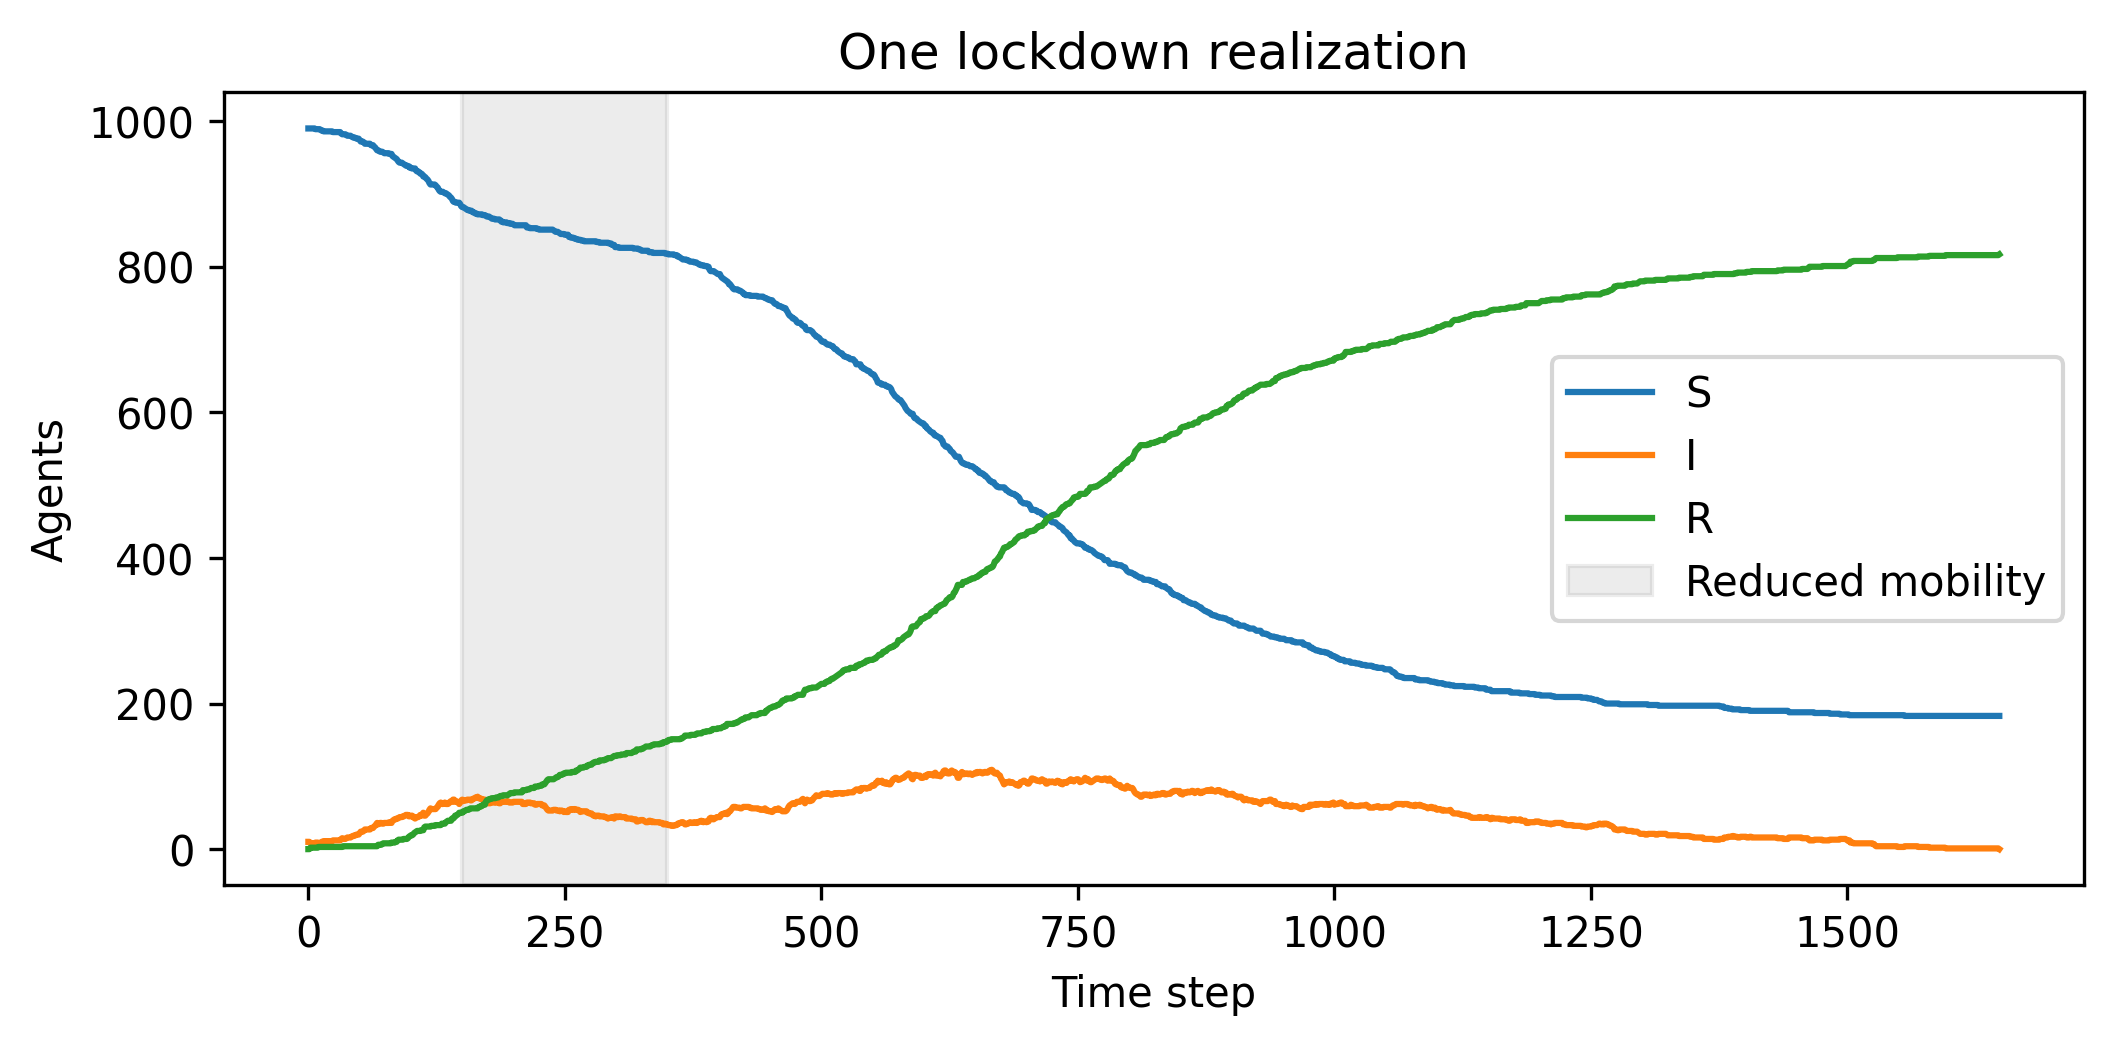

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.5), dpi=300)

for name in "SIR":
    ax.plot(lockdown["time"], lockdown[name], label=name)
ax.axvspan(
    lockdown_start, lockdown_start + lockdown_duration,
    alpha=0.15, color="gray", label="Reduced mobility"
)
ax.set(
    xlabel="Time step", 
    ylabel="Agents", 
    title="One lockdown realization"
)

ax.legend()
plt.show()

Let's compare different intervention timings for the lockdown.

In [6]:
start_times = [0, 80, 160, 240, 320]
repetitions = 20
mean_final = []
se_final = []
mean_peak = []
se_peak = []
completed = []

In [7]:
for start in start_times:
    final_sizes, peaks = [], []
    for _ in range(repetitions):
        run = ds.run_sir(
            n_agents=N, side=L, d=normal_d,
            beta=beta, gamma=gamma,
            lockdown_start=start, 
            lockdown_steps=lockdown_duration,
            lockdown_d=lockdown_d, 
            max_steps=6000
        )
        
        if run["ended_by_extinction"]:
            final_sizes.append(run["R"][-1])
            peaks.append(run["I"].max())
            
    completed.append(len(final_sizes))
    mean_final.append(
        np.mean(final_sizes) if (
            len(final_sizes) == repetitions
        ) else np.nan
    )
    se_final.append(
        np.std(final_sizes, ddof=1) / np.sqrt(repetitions) if (
            len(final_sizes) == repetitions
        ) else np.nan
    )
    mean_peak.append(
        np.mean(peaks) if (
            len(peaks) == repetitions 
        ) else np.nan
    )
    se_peak.append(
        np.std(peaks, ddof=1) / np.sqrt(repetitions) if (
            len(peaks) == repetitions
        ) else np.nan
    )
print("Completed runs at each start time:", completed)

Completed runs at each start time: [20, 20, 20, 20, 20]


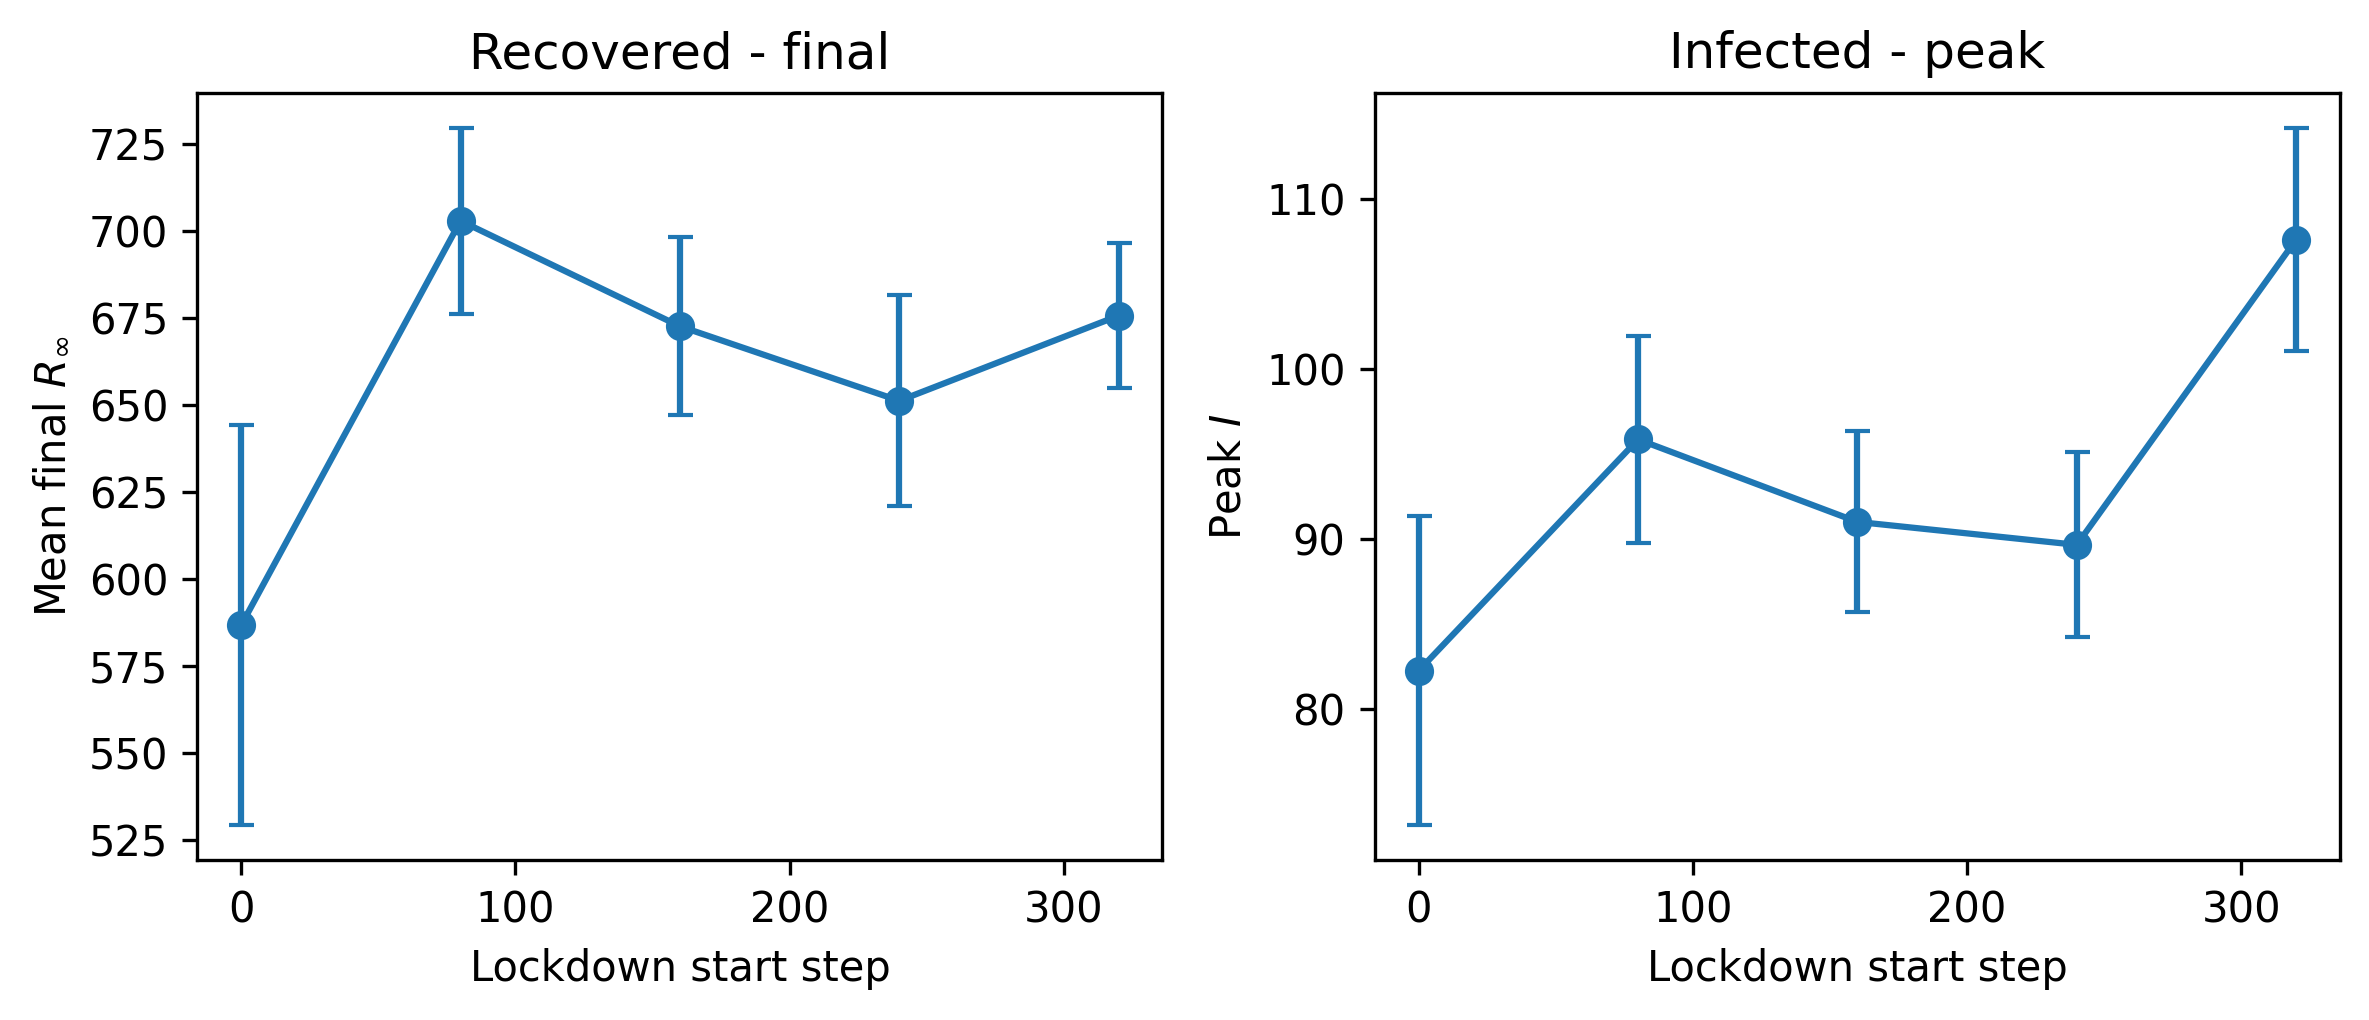

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(8, 3.5), dpi=300)

ax[0].errorbar(
    start_times, mean_final, yerr=se_final, 
    fmt="o-", capsize=3
)
ax[0].set(
    xlabel="Lockdown start step", 
    ylabel="Mean final $R_\infty$",
    title="Recovered - final"
)

ax[1].errorbar(
    start_times, mean_peak, yerr=se_peak, 
    fmt="o-", capsize=3
)
ax[1].set(
    xlabel="Lockdown start step", 
    ylabel="Peak $I$",
    title="Infected - peak"
)

plt.tight_layout()
plt.show()

Let's calculate the **no-lockdown baseline**.

In [9]:
baseline_sizes = [] 
baseline_peaks = []
for _ in range(repetitions):
    run = ds.run_sir(
        n_agents=N, side=L, d=normal_d,
        beta=beta, gamma=gamma, 
        max_steps=6000
    )
    if run["ended_by_extinction"]:
        baseline_sizes.append(run["R"][-1])
        baseline_peaks.append(run["I"].max())
        
print("Baseline completed:", len(baseline_sizes), "of", repetitions)

print(
    "Baseline mean R:", 
    np.mean(baseline_sizes) if baseline_sizes else "not available"
)

Baseline completed: 20 of 20
Baseline mean R: 751.7


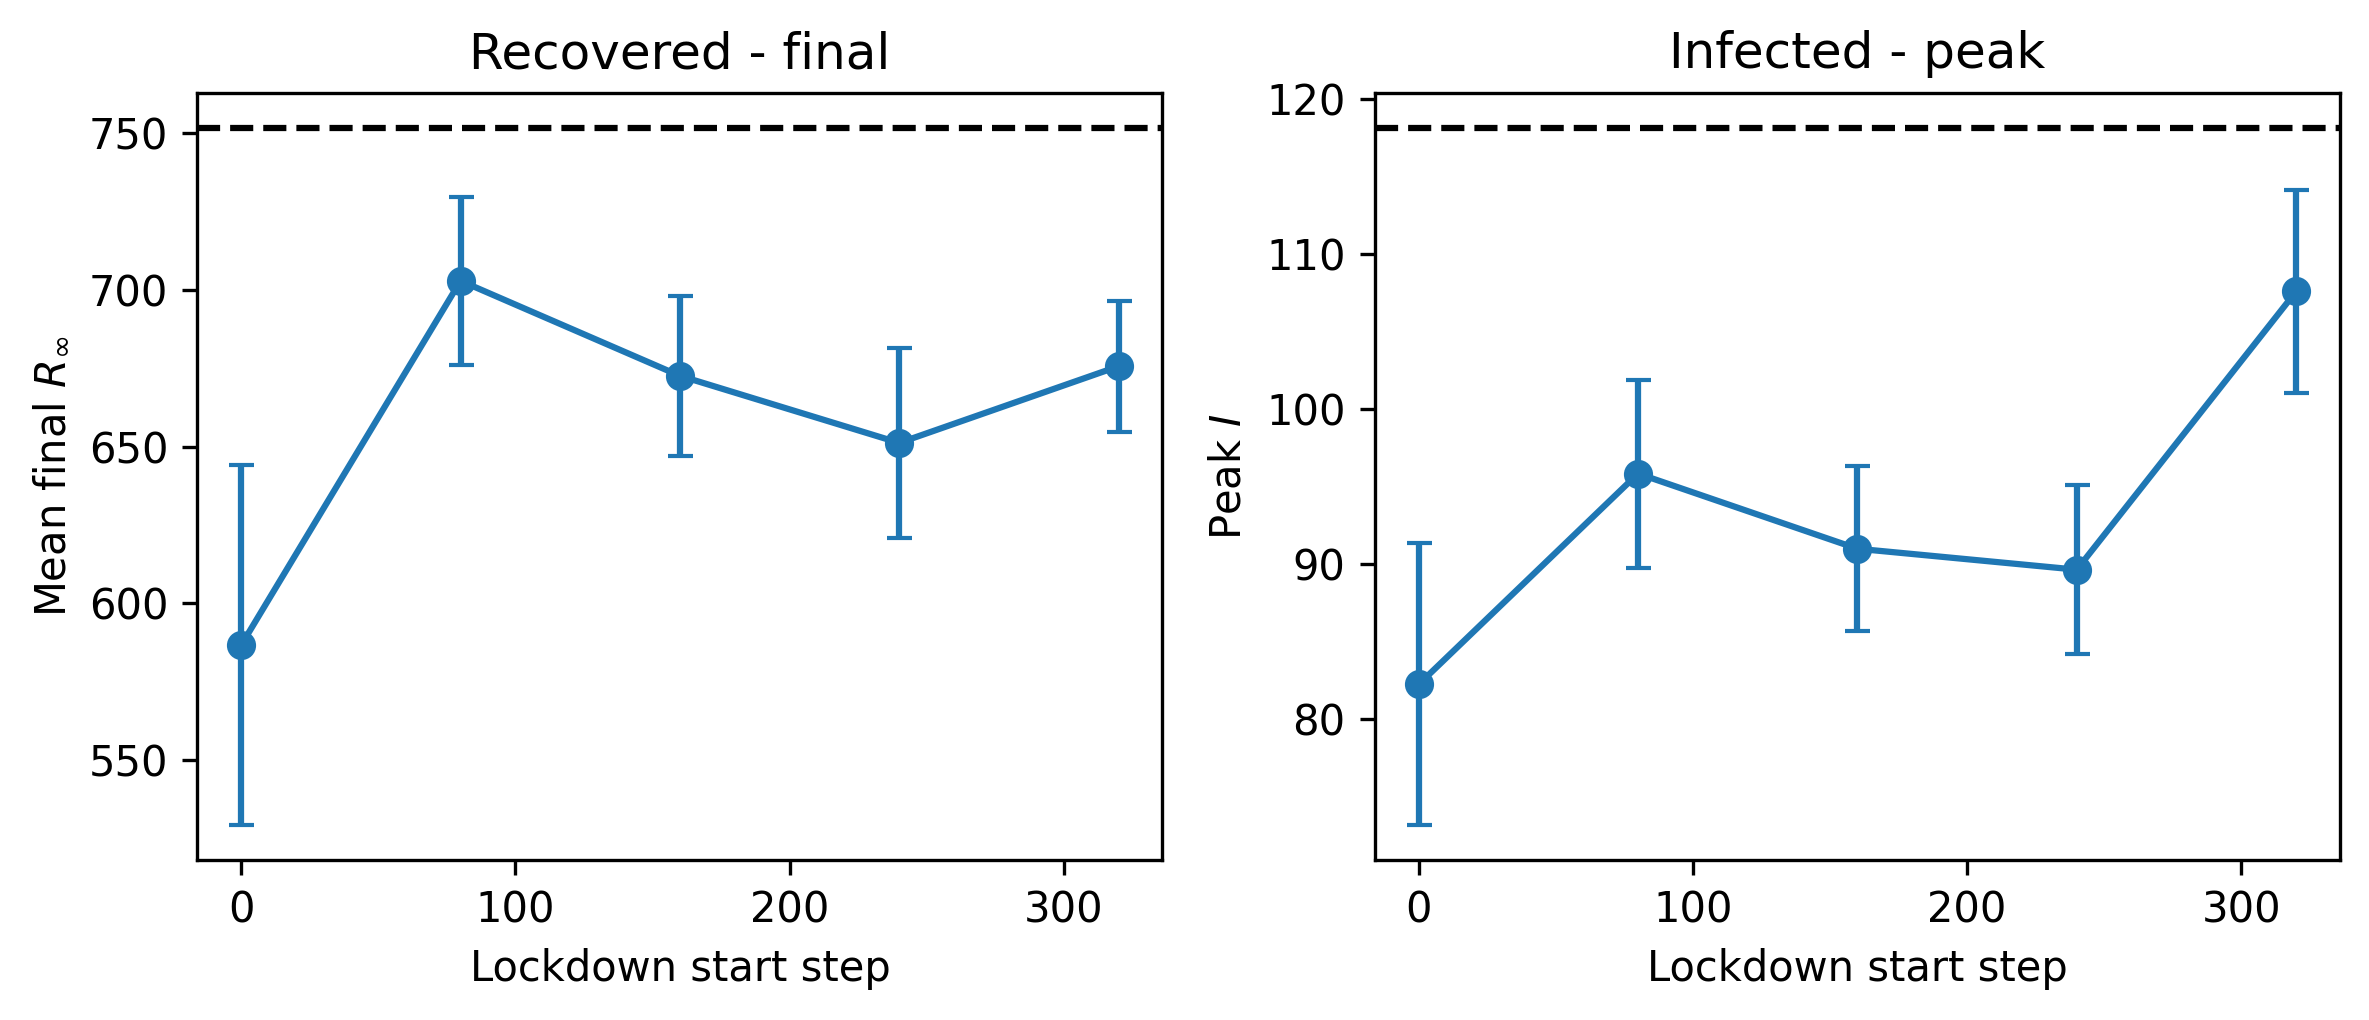

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(8, 3.5), dpi=300)

ax[0].errorbar(
    start_times, mean_final, yerr=se_final, 
    fmt="o-", capsize=3
)
ax[0].axhline(
    np.mean(baseline_sizes), color="black", linestyle="--",
    label="No lockdown (mean)"
)

ax[0].set(
    xlabel="Lockdown start step", 
    ylabel="Mean final $R_\infty$",
    title="Recovered - final"
)

ax[1].errorbar(
    start_times, mean_peak, yerr=se_peak, 
    fmt="o-", capsize=3
)
ax[1].axhline(
    np.mean(baseline_peaks), color="black", linestyle="--",
    label="No lockdown (mean)"
)

ax[1].set(
    xlabel="Lockdown start step", 
    ylabel="Peak $I$",
    title="Infected - peak"
)

plt.tight_layout()
plt.show()

Let's see an animation of the lockdown process

In [11]:
import ds_visualize as vis

pygame 2.5.2 (SDL 2.28.3, Python 3.8.5)
Hello from the pygame community. https://www.pygame.org/contribute.html


In [12]:
animation_history = vis.animate_sir(
    n_agents=600, 
    side=70, 
    beta=beta, 
    gamma=gamma,
    max_steps=240, 
    steps_per_frame=1,
    window_size=200,
    lockdown_start=90, 
    lockdown_steps=100,
    lockdown_d=lockdown_d
)

print("Rendered steps:", len(animation_history) - 1)

Rendered steps: 240


<a id="questions"></a>
## Questions

- [Q9: Lockdown strategies](#q9)

- [Q10: Final number of recovered](#q10)

- [Q11: Peak of infected](#q11)


<a id="q9"></a>
### Q9: Lockdown strategies

[Go back to questions](#questions)

**a.** There are several ways to implement lockdown strategies. Think of a different strategy and explain how you would implement it in the code.

**b.** Assume the recovery rate is related to the mobility of the agents. For example, assume that the infection rate is `beta = 0.5`, and that `gamma = 0.1 * d`. Is the lockdown mechanism explained in this notebook effective in *containing* the epidemic?

**c.** Assume that the lockdown (i.e., the reduced mobility) is imposed on infected agent only. Would this be effective? Explain your reasoning.


<a id="q10"></a>
### Q10: Final number of recovered

[Go back to questions](#questions)

**a.** Consider a SIRD model, with low mortality rate `mu = 0.001`. Would a lockdown strategy like the one described here be effective in lowering the total number of deaths? Explain you reasoning.

**b.** In the case of a SIRS model, how would you set the duration of the lockdown to minimize the total number of recovery events? Explain how you would implement your strategy in the code.


<a id="q11"></a>
### Q11: Peak of infected

[Go back to questions](#questions)

**a.** The parameters `N`, `L`, `beta`, `gamma`, `d` are fixed. How long would you set the duration of the lock-down to *flatten* the peak of the infected?

**b.** Instead of reducing the mobility `d` during the lockdown, you distribute masks, which lower the `beta`. How would you implement this in the code?

**c.** Does a smaller `beta` help in containing the peak of the infected? Explain your reasoning.
